# Phase 1 — Dataset inspection, preprocessing and splits

Goal: understand the SEN2NAIP cross-sensor pairs, define the preprocessing every later phase will use, and fix a leakage-free train / val / test split.

Steps:
1. Build a metadata table for all pairs.
2. Confirm the band order (R, G, B, NIR = SEN2SR's B04, B03, B02, B08).
3. Choose how HR (8-bit NAIP) is converted to reflectance.
4. Read every pair once: integrity checks, HR→reflectance coefficients, fit quality, LR–HR offset.
5. Spatially grouped split.
6. Save everything to `dataset_index.csv` and define `load_pair`, the loader later notebooks copy.
7. Visual check and tests.

## Settings

In [1]:
DATA_ROOT = "sen2naip/cross-sensor"
INDEX_CSV = "dataset_index.csv"     # output of this notebook (committed; small)

SCALE = 4
LR_SIZE, HR_SIZE = 121, 484
LR_PIXEL, HR_PIXEL = 10.0, 2.5
REFLECTANCE_DIVISOR = 10_000
BANDS = ["B04", "B03", "B02", "B08"]   # R, G, B, NIR (verified in step 2)

FIT_BLUR_SIGMA = 2.0                # HR px; Gaussian blur before 4x4 averaging when fitting HR->LR (chosen in step 3)
LOW_FIT_R2 = 0.5                    # flag tiles whose worst band fits worse than this

SPLIT_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}
SPLIT_SEEDS = range(200)          # candidate grouped splits; the most balanced one is kept (step 5)
BALANCE_FEATURES = ["brightness", "ndvi", "contrast", "fit_r2_min", "shift_lr_px", "qa1"]

In [2]:
import json, warnings
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from scipy.ndimage import gaussian_filter
from scipy.stats import ks_2samp
from skimage.registration import phase_cross_correlation
from tqdm import tqdm

warnings.filterwarnings("ignore")
rois = sorted(Path(DATA_ROOT).glob("ROI_*"))
print(len(rois), "pairs")

2851 pairs


## 1. Metadata table

In [3]:
rows = []
for roi in rois:
    m = json.loads((roi / "metadata.json").read_text())
    t = [float(v) for v in m["proj:transform"].split(",")]
    rows.append({
        "folder": roi.name,
        "roi_id": m["roi_id"],
        "s2_id": m["s2_id"],
        "mgrs_tile": m["s2_id"].split("_")[5],
        "naip_id": m["naip_id"],
        "s2_date": m["s2_date"],
        "naip_date": m["naip_date"],
        "epsg": m["proj:epsg"],
        "x_min": t[2], "y_max": t[5],
        "qa1": m["QA1"], "qa2": m["QA2"],
    })
df = pd.DataFrame(rows)
df["date_gap_days"] = (pd.to_datetime(df.s2_date) - pd.to_datetime(df.naip_date)).dt.days.abs()
df["year"] = df.s2_date.str[:4]

print("unique roi_id:", df.roi_id.nunique(), "| MGRS tiles:", df.mgrs_tile.nunique(), "| UTM zones:", df.epsg.nunique())
print("date gap (days):", df.date_gap_days.value_counts().to_dict(), "| years:", df.year.value_counts().sort_index().to_dict())
df.head()

unique roi_id: 2323 | MGRS tiles: 626 | UTM zones: 10
date gap (days): {0: 1664, 1: 1187} | years: {'2019': 1004, '2020': 879, '2021': 952, '2022': 16}


,folder,roi_id,s2_id,mgrs_tile,naip_id,s2_date,naip_date,epsg,x_min,y_max,qa1,qa2,date_gap_days,year
0,ROI_0000,ROI_00002,S2A_MSIL2A_20190909T174911_N0213_R141_T13SCB_2...,T13SCB,m_3710663_nw_13_060_20190909,2019-09-09,2019-09-09,32613,390530.0,4107240.0,0.653952,1.817469,0,2019
1,ROI_0001,ROI_00004,S2A_MSIL2A_20200703T184921_N0214_R113_T10TFQ_2...,T10TFQ,m_4412116_se_10_060_20200703,2020-07-03,2020-07-03,32610,657140.0,4960540.0,0.343426,0.880230,0,2020
2,ROI_0002,ROI_00006,S2A_MSIL2A_20210917T182021_N0301_R127_T11TQK_2...,T11TQK,m_4411330_se_12_060_20210917,2021-09-17,2021-09-17,32611,793610.0,4935100.0,0.215198,0.695022,0,2021
3,ROI_0003,ROI_00006,S2A_MSIL2A_20210917T182021_N0301_R127_T11TQK_2...,T11TQK,m_4411338_ne_12_060_20210917,2021-09-17,2021-09-17,32611,793610.0,4933900.0,0.294030,0.960194,0,2021
4,ROI_0004,ROI_00007,S2A_MSIL2A_20210829T174911_N0301_R141_T13TEL_2...,T13TEL,m_4510335_nw_13_060_20210830,2021-08-29,2021-08-30,32613,600620.0,5038230.0,0.543239,0.935708,1,2021


## 2. Band order

NAIP is distributed as R, G, B, NIR. Two checks that the LR bands follow the same order:
- each LR band should correlate best with the same-index HR band;
- vegetation (high NDVI) should show the textbook signature: green > red, blue < green, NIR much higher.

In [4]:
def read(path):
    with rasterio.open(path) as src:
        return src.read().astype(np.float64)

corr = np.zeros((4, 4)); veg = []
sample = rois[::10]
for roi in sample:
    lr = np.clip(read(roi / "lr.tif") / REFLECTANCE_DIVISOR, 0, None)
    hr_down = read(roi / "hr.tif").reshape(4, LR_SIZE, SCALE, LR_SIZE, SCALE).mean((2, 4))
    corr += np.corrcoef(lr.reshape(4, -1), hr_down.reshape(4, -1))[:4, 4:]
    ndvi = (lr[3] - lr[0]) / (lr[3] + lr[0] + 1e-9)
    if (ndvi > 0.6).sum() > 200:
        veg.append([lr[b][ndvi > 0.6].mean() for b in range(4)])
corr /= len(sample); veg = np.array(veg)

print("LR band (rows) vs HR band (cols) mean correlation:")
print(pd.DataFrame(corr, index=BANDS, columns=BANDS).round(2))
print(f"\nvegetation tiles: {len(veg)} | mean reflectance {dict(zip(BANDS, veg.mean(0).round(4)))}")
print(f"green > red in {(veg[:, 1] > veg[:, 0]).mean():.0%} | blue < green in {(veg[:, 2] < veg[:, 1]).mean():.0%} | NIR > all visible in {(veg[:, 3] > veg[:, :3].max(1)).mean():.0%}")

LR band (rows) vs HR band (cols) mean correlation:
      B04   B03   B02   B08
B04  0.86  0.81  0.82  0.26
B03  0.81  0.85  0.82  0.35
B02  0.79  0.81  0.86  0.23
B08  0.25  0.35  0.22  0.82

vegetation tiles: 149 | mean reflectance {'B04': np.float64(0.0432), 'B03': np.float64(0.0582), 'B02': np.float64(0.0325), 'B08': np.float64(0.3322)}
green > red in 98% | blue < green in 100% | NIR > all visible in 100%


## 3. Converting HR to reflectance

HR is 8-bit NAIP DN; LR is Sentinel-2 reflectance. For each pair and band we fit `LR ≈ a · degrade(HR) + b` at 10 m and apply `a · HR + b` at 2.5 m. `degrade` = Gaussian blur, then 4×4 average. The blur makes the HR look more like Sentinel-2's optical blur (PSF); it is used only for the fit. Below: which blur width fits best (subsample).

*Caveat:* the HR reference is calibrated against the LR it is paired with, so its coarse radiometry follows Sentinel-2. This is applied identically to every method being compared.

In [5]:
def degrade(hr, sigma=FIT_BLUR_SIGMA):
    """HR [4, 484, 484] -> [4, 121, 121]: optional Gaussian blur, then 4x4 mean."""
    if sigma > 0:
        hr = np.stack([gaussian_filter(b, sigma) for b in hr])
    return hr.reshape(hr.shape[0], LR_SIZE, SCALE, LR_SIZE, SCALE).mean((2, 4))

def fit_linear(x, y):
    """Least squares y ~ a*x + b. Returns a, b, R^2, RMSE."""
    A = np.c_[x.ravel(), np.ones(x.size)]
    (a, b), *_ = np.linalg.lstsq(A, y.ravel(), rcond=None)
    resid = y.ravel() - A @ (a, b)
    return a, b, 1 - (resid**2).sum() / ((y - y.mean())**2).sum(), np.sqrt((resid**2).mean())

sigma_table = {}
for sigma in [0, 1, 2, 3, 4, 6]:
    r2 = []
    for roi in sample:
        lr = np.clip(read(roi / "lr.tif") / REFLECTANCE_DIVISOR, 0, None)
        hr_d = degrade(read(roi / "hr.tif"), sigma)
        r2.append([fit_linear(hr_d[b], lr[b])[2] for b in range(4)])
    r2 = np.array(r2)
    sigma_table[sigma] = {**dict(zip(BANDS, np.median(r2, 0).round(3))), "tiles_any_R2<0.5": round((r2.min(1) < LOW_FIT_R2).mean(), 3)}
pd.DataFrame(sigma_table).T.rename_axis("blur sigma (HR px)")

,B04,B03,B02,B08,tiles_any_R2<0.5
blur sigma (HR px),,,,,
0,0.803,0.790,0.805,0.755,0.245
1,0.828,0.814,0.835,0.790,0.210
2,0.846,0.833,0.854,0.825,0.192
3,0.841,0.827,0.841,0.830,0.185
4,0.823,0.801,0.813,0.816,0.192
6,0.774,0.745,0.754,0.767,0.241


## 4. Read every pair: integrity, HR→reflectance coefficients, fit quality, LR–HR offset

In [6]:
records = []
for roi in tqdm(rois):
    with rasterio.open(roi / "lr.tif") as L, rasterio.open(roi / "hr.tif") as H:
        lr_raw, hr = L.read(), H.read().astype(np.float64)
        rec = {
            "shape_ok": L.shape == (LR_SIZE, LR_SIZE) and H.shape == (HR_SIZE, HR_SIZE) and L.count == H.count == 4,
            "dtype_ok": L.dtypes[0] == "int32" and H.dtypes[0] == "uint8",
            "crs_ok": L.crs == H.crs and L.crs.to_epsg() == int(df.epsg[len(records)]),
            "bounds_ok": np.allclose(tuple(L.bounds), tuple(H.bounds)),
            "transform_ok": np.allclose(H.transform[:6], (HR_PIXEL, 0, L.transform.c, 0, -HR_PIXEL, L.transform.f))
                            and np.isclose(L.transform.a, LR_PIXEL),
            "lr_nodata_px": int((lr_raw == L.nodata).sum()),
            "lr_negative_px": int((lr_raw < 0).sum()),
            "hr_zero_px": int((hr == 0).all(0).sum()),
        }
    lr = np.clip(lr_raw / REFLECTANCE_DIVISOR, 0, None)
    ndvi = (lr[3] - lr[0]) / (lr[3] + lr[0] + 1e-9)
    rec.update({"brightness": lr[:3].mean(), "ndvi": ndvi.mean(), "contrast": lr.std(axis=(1, 2)).mean()})
    hr_d = degrade(hr)
    for b, name in enumerate(BANDS):
        a, c, r2, rmse = fit_linear(hr_d[b], lr[b])
        rec.update({f"a_{name}": a, f"b_{name}": c, f"r2_{name}": r2, f"rmse_{name}": rmse})
    # sub-pixel LR offset between LR and harmonised, degraded HR (band mean)
    hr_ref_d = np.stack([rec[f"a_{n}"] * hr_d[b] + rec[f"b_{n}"] for b, n in enumerate(BANDS)])
    shift, _, _ = phase_cross_correlation(lr.mean(0), hr_ref_d.mean(0), upsample_factor=10)
    rec.update({"shift_y_lr_px": shift[0], "shift_x_lr_px": shift[1]})
    records.append(rec)

df = pd.concat([df, pd.DataFrame(records)], axis=1)
df["fit_r2_min"] = df[[f"r2_{b}" for b in BANDS]].min(1)
df["shift_lr_px"] = np.hypot(df.shift_y_lr_px, df.shift_x_lr_px)
df["non_positive_slope"] = (df[[f"a_{b}" for b in BANDS]] <= 0).any(axis=1)
df["low_fit"] = (df.fit_r2_min < LOW_FIT_R2) | df.non_positive_slope

checks = ["shape_ok", "dtype_ok", "crs_ok", "bounds_ok", "transform_ok"]
print({c: int(df[c].sum()) for c in checks}, "of", len(df))
print("LR nodata px:", df.lr_nodata_px.sum(), "| LR negative px:", df.lr_negative_px.sum(), "in", (df.lr_negative_px > 0).sum(), "tiles | HR all-zero px:", df.hr_zero_px.sum())

100%|██████████| 2851/2851 [00:45<00:00, 62.13it/s]


{'shape_ok': 2851, 'dtype_ok': 2851, 'crs_ok': 2851, 'bounds_ok': 2851, 'transform_ok': 2851} of 2851
LR nodata px: 0 | LR negative px: 2404 in 4 tiles | HR all-zero px: 0


## Quality summary

HR->LR fit R^2 (median per band): {'r2_B04': 0.844, 'r2_B03': 0.832, 'r2_B02': 0.852, 'r2_B08': 0.808}
tiles flagged low_fit (worst-band R^2 < 0.5 or a non-positive slope): 422 (14.8%)
non-positive slopes: 7 tiles (all flagged)
LR-HR offset (LR px): median 0.36 | p95 0.71 | max 1.17
low-fit share: same-day 0.129 | 1-day gap 0.175


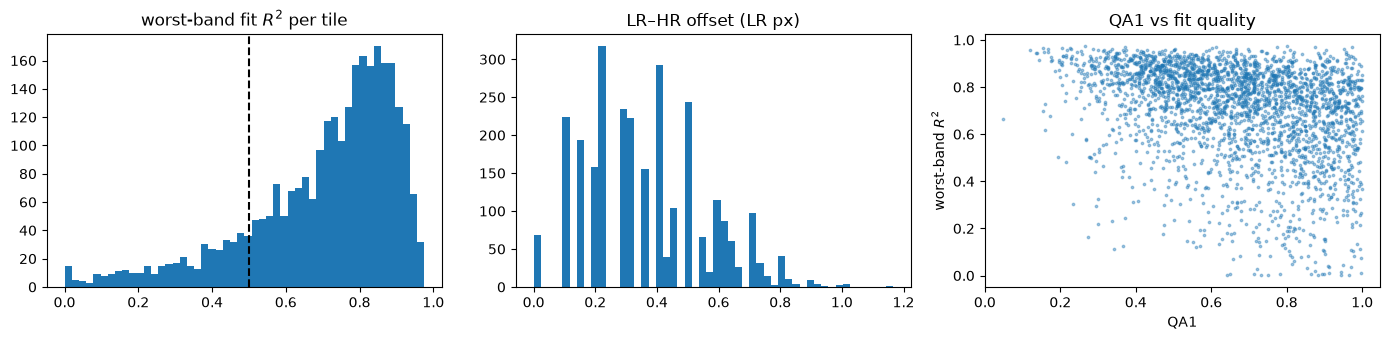

In [7]:
r2_cols = [f"r2_{b}" for b in BANDS]
print("HR->LR fit R^2 (median per band):", df[r2_cols].median().round(3).to_dict())
print(f"tiles flagged low_fit (worst-band R^2 < {LOW_FIT_R2} or a non-positive slope): {df.low_fit.sum()} ({df.low_fit.mean():.1%})")
print("non-positive slopes:", int(df.non_positive_slope.sum()), "tiles (all flagged)")
print("LR-HR offset (LR px): median", round(df.shift_lr_px.median(), 2), "| p95", round(df.shift_lr_px.quantile(0.95), 2), "| max", round(df.shift_lr_px.max(), 2))
print("low-fit share: same-day", round(df[df.date_gap_days == 0].low_fit.mean(), 3), "| 1-day gap", round(df[df.date_gap_days == 1].low_fit.mean(), 3))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].hist(df.fit_r2_min.clip(-0.5), bins=50); ax[0].axvline(LOW_FIT_R2, c="k", ls="--"); ax[0].set_title("worst-band fit $R^2$ per tile")
ax[1].hist(df.shift_lr_px, bins=50); ax[1].set_title("LR–HR offset (LR px)")
ax[2].scatter(df.qa1, df.fit_r2_min.clip(-0.5), s=3, alpha=0.4); ax[2].set_xlabel("QA1"); ax[2].set_ylabel("worst-band $R^2$"); ax[2].set_title("QA1 vs fit quality")
plt.tight_layout(); plt.show()

## 5. Spatially grouped split

Pairs are linked if they share a Sentinel-2 MGRS tile, a `roi_id` (same place, other date), or overlapping / touching footprints. Connected groups are assigned whole to train / val / test, so no place or neighbourhood appears in two splits.

With only ~600 groups, a single random assignment can leave the splits unbalanced (an earlier seed gave a test set that was clearly greener, darker and worse aligned than train). So 200 candidate grouped splits are generated and the one with the **smallest worst-case KS statistic** between train and val/test over scene properties (brightness, NDVI, contrast, fit quality, offset, QA1) is kept. Only data properties are used — never model results.

In [8]:
def spatial_groups(df):
    parent = list(range(len(df)))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]; i = parent[i]
        return i
    def union(i, j):
        parent[find(i)] = find(j)

    for key in ["mgrs_tile", "roi_id"]:
        for idx in df.groupby(key).indices.values():
            for j in idx[1:]:
                union(idx[0], j)
    extent = LR_SIZE * LR_PIXEL
    for idx in df.groupby("epsg").indices.values():
        x0, y1 = df.x_min.values[idx], df.y_max.values[idx]
        for k, i in enumerate(idx):   # overlap or touch (closed intervals)
            near = (np.abs(x0 - x0[k]) <= extent) & (np.abs(y1 - y1[k]) <= extent)
            for j in idx[near]:
                union(i, j)
    roots = [find(i) for i in range(len(df))]
    return pd.Series(pd.factorize(pd.Series(roots))[0], index=df.index)

def assign_splits(groups, fractions, seed):
    """Shuffle groups, then give each to the split furthest below its target size."""
    sizes = groups.value_counts()
    order = np.random.default_rng(seed).permutation(sizes.index.values)
    count = {s: 0 for s in fractions}; total = len(groups); split_of = {}
    for g in order:
        s = max(fractions, key=lambda s: fractions[s] - count[s] / total)
        split_of[g] = s; count[s] += sizes[g]
    return groups.map(split_of)

def imbalance(df, split):
    """Worst KS statistic between train and val / test over the balance features."""
    train = split == "train"
    return max(ks_2samp(df.loc[train, f], df.loc[split == s, f]).statistic for f in BALANCE_FEATURES for s in ["val", "test"])

df["group"] = spatial_groups(df)
scores = {seed: imbalance(df, assign_splits(df.group, SPLIT_FRACTIONS, seed)) for seed in tqdm(SPLIT_SEEDS)}
SPLIT_SEED = min(scores, key=scores.get)
df["split"] = assign_splits(df.group, SPLIT_FRACTIONS, SPLIT_SEED)
print("groups:", df.group.nunique(), "| largest group:", df.group.value_counts().max(), "pairs")
print(f"chosen seed {SPLIT_SEED}: worst KS statistic {scores[SPLIT_SEED]:.3f} (median over seeds {np.median(list(scores.values())):.3f}, worst {max(scores.values()):.3f})")
summary = df.groupby("split").agg(pairs=("folder", "size"), groups=("group", "nunique"), mgrs_tiles=("mgrs_tile", "nunique"),
                                  utm_zones=("epsg", "nunique"), low_fit=("low_fit", "mean"), median_r2=("fit_r2_min", "median"),
                                  same_day=("date_gap_days", lambda s: (s == 0).mean()), median_qa1=("qa1", "median"))
summary["share"] = summary.pairs / len(df)
display(summary.loc[["train", "val", "test"]].round(3))

balance = pd.DataFrame([{"feature": f, "split": s, "median": df.loc[df.split == s, f].median(), "median_train": df.loc[df.split == "train", f].median(),
                         "KS_p": ks_2samp(df.loc[df.split == "train", f], df.loc[df.split == s, f]).pvalue}
                        for f in BALANCE_FEATURES for s in ["val", "test"]])
balance.round(4)

100%|██████████| 200/200 [00:01<00:00, 111.96it/s]

groups: 614 | largest group: 27 pairs
chosen seed 89: worst KS statistic 0.059 (median over seeds 0.113, worst 0.272)


,pairs,groups,mgrs_tiles,utm_zones,low_fit,median_r2,same_day,median_qa1,share
split,,,,,,,,,
train,1997,435,445,10,0.156,0.762,0.586,0.681,0.700
val,426,99,99,10,0.122,0.765,0.596,0.692,0.149
test,428,80,82,9,0.138,0.751,0.558,0.665,0.150


,feature,split,median,median_train,KS_p
0,brightness,val,0.0986,0.1000,0.8204
1,brightness,test,0.0995,0.1000,0.1780
2,ndvi,val,0.2948,0.3214,0.3016
3,ndvi,test,0.3048,0.3214,0.1584
4,contrast,val,0.0243,0.0245,0.1969
5,contrast,test,0.0236,0.0245,0.3005
6,fit_r2_min,val,0.7654,0.7616,0.4722
7,fit_r2_min,test,0.7511,0.7616,0.5796
8,shift_lr_px,val,0.3606,0.3162,0.3528
9,shift_lr_px,test,0.3162,0.3162,0.8355


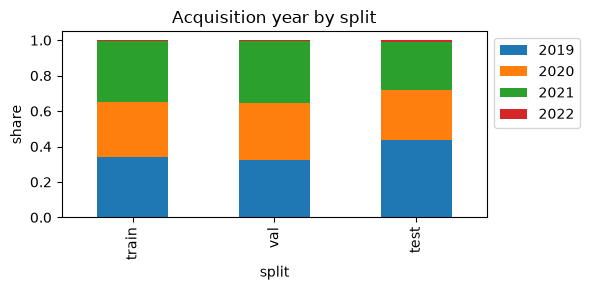

In [9]:
fig, ax = plt.subplots(figsize=(6, 3))
pd.crosstab(df.split, df.year, normalize="index").loc[["train", "val", "test"]].plot.bar(stacked=True, ax=ax)
ax.set_ylabel("share"); ax.set_title("Acquisition year by split"); ax.legend(bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

## 6. Save the index and define the loader

In [10]:
index_cols = (["folder", "roi_id", "mgrs_tile", "epsg", "x_min", "y_max", "s2_date", "naip_date", "date_gap_days", "qa1", "qa2", "group", "split"]
              + [f"{p}_{b}" for p in ["a", "b", "r2", "rmse"] for b in BANDS]
              + ["brightness", "ndvi", "contrast", "fit_r2_min", "non_positive_slope", "low_fit", "shift_y_lr_px", "shift_x_lr_px", "shift_lr_px"])
df[index_cols].to_csv(INDEX_CSV, index=False, float_format="%.6g")
print("saved", INDEX_CSV, df[index_cols].shape)

saved dataset_index.csv (2851, 38)


`load_pair` is the single definition of preprocessing. Later notebooks copy this cell.

- **LR:** int32 / 10 000, clipped at 0 → float32 reflectance `[4, 121, 121]`.
- **HR:** `a · DN + b` per band (coefficients from the index), clipped at 0 → float32 reflectance `[4, 484, 484]`.
- Band order unchanged: B04, B03, B02, B08.

In [11]:
def load_pair(row, data_root=DATA_ROOT):
    """Return (lr, hr) float32 reflectance arrays for one row of dataset_index.csv."""
    roi = Path(data_root) / row["folder"]
    with rasterio.open(roi / "lr.tif") as src:
        lr = np.clip(src.read().astype(np.float32) / REFLECTANCE_DIVISOR, 0, None)
    with rasterio.open(roi / "hr.tif") as src:
        hr = src.read().astype(np.float32)
    a = np.array([row[f"a_{b}"] for b in BANDS], np.float32)[:, None, None]
    b = np.array([row[f"b_{b}"] for b in BANDS], np.float32)[:, None, None]
    return lr, np.clip(a * hr + b, 0, None)

index = pd.read_csv(INDEX_CSV)
lr, hr = load_pair(index.iloc[0])
print("lr", lr.shape, lr.dtype, lr.min().round(4), lr.max().round(4), "| hr", hr.shape, hr.dtype, hr.min().round(4), hr.max().round(4))

lr (4, 121, 121) float32 0.0072 0.2469 | hr (4, 484, 484) float32 0.0165 0.2145


## 7. Visual check

LR, raw HR (DN, own stretch) and harmonised HR (same stretch as LR) for a good fit, a median fit and a poor fit.

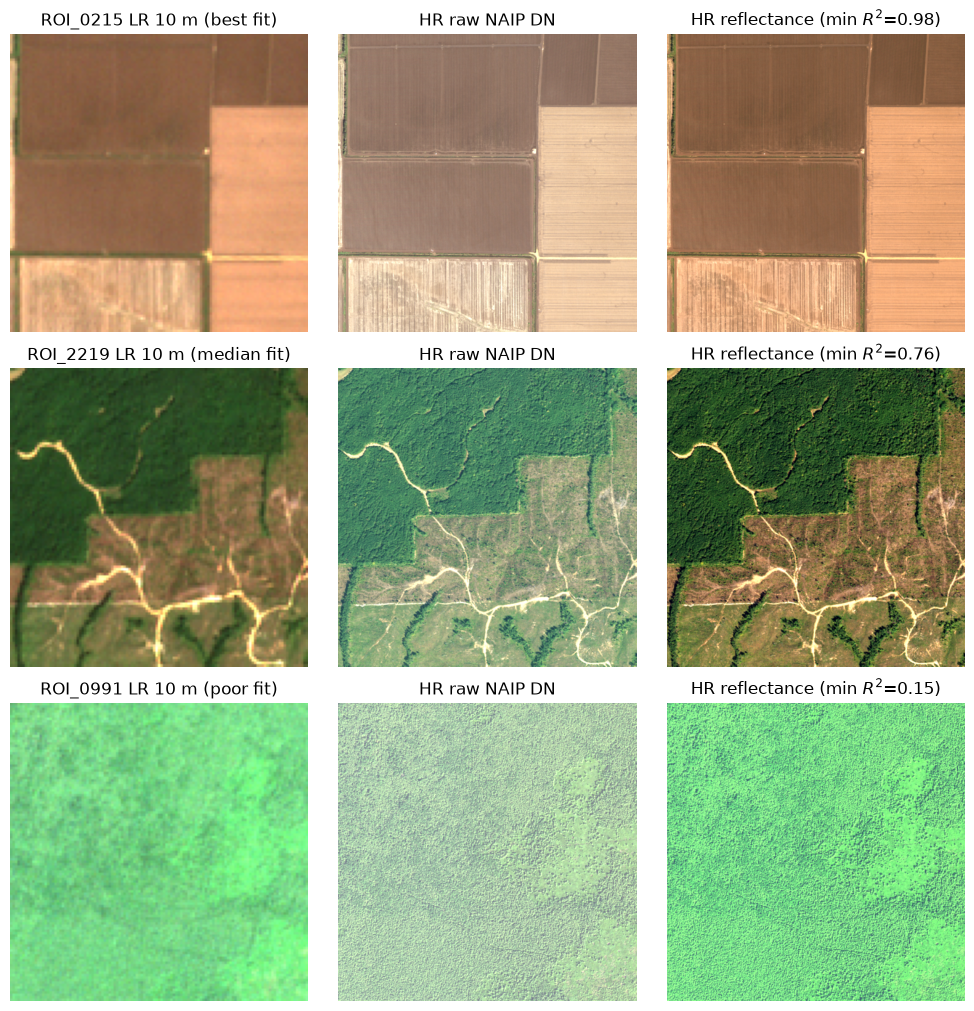

In [12]:
def rgb(x, scale):
    return np.clip(x[:3].transpose(1, 2, 0) / scale, 0, 1)

by_fit = index.sort_values("fit_r2_min")
picks = {"best fit": by_fit.iloc[-1], "median fit": by_fit.iloc[len(by_fit) // 2], "poor fit": by_fit.iloc[len(by_fit) // 50]}
fig, ax = plt.subplots(len(picks), 3, figsize=(10, 3.4 * len(picks)))
for r, (label, row) in enumerate(picks.items()):
    lr, hr = load_pair(row)
    with rasterio.open(Path(DATA_ROOT) / row.folder / "hr.tif") as src:
        hr_raw = src.read().astype(np.float32)
    s = np.percentile(lr[:3], 99)
    ax[r, 0].imshow(rgb(lr, s)); ax[r, 0].set_title(f"{row.folder} LR 10 m ({label})")
    ax[r, 1].imshow(rgb(hr_raw, np.percentile(hr_raw[:3], 99))); ax[r, 1].set_title("HR raw NAIP DN")
    ax[r, 2].imshow(rgb(hr, s)); ax[r, 2].set_title(f"HR reflectance (min $R^2$={row.fit_r2_min:.2f})")
for a in ax.ravel():
    a.axis("off")
plt.tight_layout(); plt.show()

## Tests

In [13]:
results = {}

def test(name):
    def wrap(fn):
        try:
            fn(); results[name] = "PASS"
        except Exception as e:
            results[name] = f"FAIL: {type(e).__name__}: {e}"
        print(f"{results[name][:4]}  {name}" + ("" if results[name] == "PASS" else f"  -> {results[name]}"))
    return wrap

@test("index has one row per pair, unique folders")
def _():
    assert len(index) == len(rois) == 2851 and index.folder.is_unique

@test("all pairs pass shape / dtype / CRS / bounds / transform checks")
def _():
    assert df[checks].all().all(), df[checks].sum().to_dict()

@test("HR transform is the LR transform with pixel size / 4 (same origin)")
def _():
    for roi in rois[::100]:
        with rasterio.open(roi / "lr.tif") as L, rasterio.open(roi / "hr.tif") as H:
            assert np.allclose(H.transform[:6], (L.transform.a / SCALE, 0, L.transform.c, 0, L.transform.e / SCALE, L.transform.f))

@test("band order: same-index bands correlate best; vegetation signature holds")
def _():
    assert (corr.argmax(1) == np.arange(4)).all()
    assert (veg[:, 1] > veg[:, 0]).mean() > 0.9 and (veg[:, 2] < veg[:, 1]).mean() > 0.9 and (veg[:, 3] > veg[:, :3].max(1)).mean() > 0.9

@test("blur sigma used is the best of the tested values (mean of band medians)")
def _():
    score = {s: np.mean([v[b] for b in BANDS]) for s, v in sigma_table.items()}
    assert max(score, key=score.get) == FIT_BLUR_SIGMA, score

@test("split fractions within 2 percentage points of targets")
def _():
    share = index.split.value_counts(normalize=True)
    for s, f in SPLIT_FRACTIONS.items():
        assert abs(share[s] - f) < 0.02, (s, share[s])

@test("no group, MGRS tile or roi_id appears in more than one split")
def _():
    for key in ["group", "mgrs_tile", "roi_id"]:
        assert (index.groupby(key).split.nunique() == 1).all(), key

@test("no footprint in one split overlaps or touches a footprint in another split")
def _():
    extent = LR_SIZE * LR_PIXEL
    for _, g in index.groupby("epsg"):
        x, y, s = g.x_min.to_numpy(), g.y_max.to_numpy(), g.split.to_numpy(dtype=object)
        near = (np.abs(x[:, None] - x[None]) <= extent) & (np.abs(y[:, None] - y[None]) <= extent)
        assert not (near & (s[:, None] != s[None])).any()

@test("split is reproducible from the index: same groups, same seed, same split")
def _():
    groups = spatial_groups(index)
    assert assign_splits(groups, SPLIT_FRACTIONS, SPLIT_SEED).equals(index.split)
    assert not assign_splits(groups, SPLIT_FRACTIONS, SPLIT_SEED + 1).equals(index.split)

@test("split is balanced: KS p > 0.05 for every feature, train vs val and train vs test")
def _():
    assert (balance.KS_p > 0.05).all(), balance[balance.KS_p <= 0.05].to_dict("records")

@test("chosen split is the most balanced candidate")
def _():
    assert imbalance(index, index.split) <= min(scores.values()) + 1e-12

@test("load_pair: shapes, float32, finite, non-negative on 30 random pairs")
def _():
    for _, row in index.sample(30, random_state=0).iterrows():
        lr, hr = load_pair(row)
        assert lr.shape == (4, LR_SIZE, LR_SIZE) and hr.shape == (4, HR_SIZE, HR_SIZE)
        assert lr.dtype == hr.dtype == np.float32
        assert np.isfinite(lr).all() and np.isfinite(hr).all() and lr.min() >= 0 and hr.min() >= 0

@test("harmonised HR matches LR radiometry: band means within 2% (median over 30 pairs)")
def _():
    rel = []
    for _, row in index.sample(30, random_state=1).iterrows():
        lr, hr = load_pair(row)
        rel.append(np.abs(hr.mean((1, 2)) - lr.mean((1, 2))) / lr.mean((1, 2)))
    assert np.median(rel) < 0.02, np.median(rel)

@test("every tile with a non-positive slope is flagged low_fit")
def _():
    assert index.low_fit[index.non_positive_slope].all() and index.non_positive_slope.sum() > 0

@test("saved index round-trips (coefficients and flags equal in-memory values)")
def _():
    for c in ["a_B04", "b_B08", "fit_r2_min", "shift_lr_px"]:
        assert np.allclose(index[c], df[c], rtol=1e-5, atol=1e-8), c
    assert index.low_fit.equals(df.low_fit) and index.split.equals(df.split)

failed = [k for k, v in results.items() if v != "PASS"]
print(f"\n{len(results) - len(failed)}/{len(results)} tests passed")
assert not failed, failed

PASS  index has one row per pair, unique folders
PASS  all pairs pass shape / dtype / CRS / bounds / transform checks
PASS  HR transform is the LR transform with pixel size / 4 (same origin)
PASS  band order: same-index bands correlate best; vegetation signature holds
PASS  blur sigma used is the best of the tested values (mean of band medians)
PASS  split fractions within 2 percentage points of targets
PASS  no group, MGRS tile or roi_id appears in more than one split
PASS  no footprint in one split overlaps or touches a footprint in another split
PASS  split is reproducible from the index: same groups, same seed, same split
PASS  split is balanced: KS p > 0.05 for every feature, train vs val and train vs test
PASS  chosen split is the most balanced candidate
PASS  load_pair: shapes, float32, finite, non-negative on 30 random pairs
PASS  harmonised HR matches LR radiometry: band means within 2% (median over 30 pairs)
PASS  every tile with a non-positive slope is flagged low_fit
PASS  

## Findings

*(see cell outputs above for the exact numbers)*

- **Integrity:** every pair has 4×121×121 int32 LR and 4×484×484 uint8 HR with identical CRS and bounds; the HR transform is exactly the LR transform with ¼ the pixel size. No nodata or all-zero pixels; a few LR pixels are slightly negative and are clipped to 0.
- **Band order:** R, G, B, NIR in both LR and HR, i.e. SEN2SR's B04, B03, B02, B08 — no reordering needed.
- **HR → reflectance:** per-pair, per-band linear fit against LR after a σ = 2 HR-px Gaussian blur + 4×4 mean (best of the tested blurs). Most pairs fit well; low-fit pairs (worst band R² < 0.5, or a non-positive slope) are **flagged, not removed**, and used for sensitivity analysis later.
- **Offsets:** LR–HR offsets are mostly well below one LR pixel; recorded per pair for later sensitivity checks.
- **Split:** 70 / 15 / 15 over spatially connected groups (shared MGRS tile, shared `roi_id`, or touching footprints). No place or neighbourhood appears in two splits. Of 200 candidate grouped splits, the one best balanced on scene properties is used. The test split must not be used until the final evaluation.
- **Output:** `dataset_index.csv` (metadata, split, coefficients, quality flags) + `load_pair`, the shared preprocessing for all later phases.